In [1]:
"""
Plotting changes in zonal/meridional currents in e3smv1 to understand heat budget better
May 2025
Shay Magahey
UCSB

Update May 2025 to be less stupid
"""

'\nPlotting changes in zonal/meridional currents in e3smv1 to understand heat budget better\nMay 2025\nShay Magahey\nUCSB\n\nUpdate May 2025 to be less stupid\n'

In [2]:
import cftime
import xarray as xr
import numpy as np
import glob
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
#from ultimate_composite_functions import select_events,var_composites,plot_composites
import time
start=time.time()
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites,plot_composites,quarter_only

In [3]:
# before this: run exporttonc.py to get nc files for whatever you want to plot

In [4]:
# input tos, time period of interest to get all EN/LN yrs during that time period

def select_events(tos,n34,regbox,strt,fin,timespi):
    # --------------------------------------------
    # Shay Magahey UCSB updated 2/14/25 for geofish project
    # tos= SST, detrended but not anomaly
    # n34 =  nino region
    # regbox= region to isolate over so you're not computing over whole globe. generally -40,40,90,300
    # strt: start year as integer
    # fin: end year as integer
    # timespi: list with strings of start/end year and month ie ['2035-01','2070-01']
    # returns the El Nino/La NIna years for each member (member by year)
    #--------------------------------------------------

    # isolate time period and nino region
    ens_n34=tos.sel(lat=slice(n34[0],n34[1]),lon=slice(n34[2],n34[3]),time=slice(timespi[0],timespi[1]))
    # isolate time period and overall region (i.e. if you were to make a map, you need mroe than n34)
    ens_sst=tos.sel(lat=slice(regbox[0],regbox[1]),lon=slice(regbox[2],regbox[3]),time=slice(timespi[0],timespi[1]))

    # calculate anomalies
    
    clim=ens_n34.groupby('time.month').mean()
    ens_n34=ens_n34.groupby('time.month')-clim  

    clim=ens_sst.groupby('time.month').mean()
    ens_sst=ens_sst.groupby('time.month')-clim

    # Isolate quarterly average SSTs, drop all non-DJF quarters. Apply to n34
    tmpdjf=ens_n34.resample(time='QS-DEC').mean(dim="time")
    tmpdjf=tmpdjf.where(tmpdjf.time.dt.month == 12,drop="True") # n34 sst
    ens_n34_djf=tmpdjf
    
    # Isolate quarterly average SSTs, drop all non-DJF quarters. Apply to whole region
    tmpdjf1=ens_sst.resample(time='QS-DEC').mean(dim="time")
    tmpdjf1=tmpdjf1.where(tmpdjf1.time.dt.month == 12,drop="True") # all sst
    ens_sst_djf=tmpdjf1

    # Calculate standard deviation across members. Isolate what years have DJF SSTA greater than 1SD (El Nino) or less than -1SD (la nina)
    tmpn34std=ens_n34_djf.std('time').mean('member').squeeze() 
    msk_en=ens_n34_djf > 1*tmpn34std
    en_evt=ens_sst_djf.where(msk_en, drop=True).squeeze()

    msk_ln=ens_n34_djf < -1*tmpn34std
    ln_evt=ens_sst_djf.where(msk_ln, drop=True).squeeze()

    yrrange=np.arange(strt,fin,1)
    enyrs_per=[]
    # Filter out nans/fill values
    
    # for each member, consider which years have Nino/nina. Replace non ENSO years with NaN, ENSO years have year value
    for i in range(len(en_evt.member)):
        A=msk_en.isel(member=i).mean('lat').mean('lon')
        
        fut=xr.where(A[0:len(yrrange)],yrrange,np.nan)
        enyrs_per.append(fut)
    ninoyrs_mem=np.stack(enyrs_per,axis=0)
    ninoyrs_mem=xr.DataArray(ninoyrs_mem).rename({'dim_0':'member','dim_1':'time'})
    lnyrs_per=[]
    for i in range(len(ln_evt.member)):
        B=msk_ln.isel(member=i).mean('lat').mean('lon')
        futln=xr.where(B[0:len(yrrange)],yrrange,np.nan)
        lnyrs_per.append(futln) 
    ninayrs_mem=np.stack(lnyrs_per,axis=0)
    ninayrs_mem=xr.DataArray(ninayrs_mem).rename({'dim_0':'member','dim_1':'time'})

    # output is member x year
    return(ninoyrs_mem,ninayrs_mem)

In [5]:
histdir='/glade/campaign/cgd/ccr/E3SMv1-LE/CMOR/historical/'   
dirssp='/glade/campaign/cgd/ccr/nanr/CMOR/E3SM-1-0/ssp370/'
regbox=[-40,40,90,300]

timespi=['1850-01','1880-01']
timesfut=['2070-01','2100-01']
#udspi=xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/uo_1850_1880_E3SMv1LE.nc')
vdspi=xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/wo_1850_1880_E3SMv1LE.nc')
#udsfut=xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/uo_2070_2100_E3SMv1LE.nc')
vdsfut=xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/wo_2070_2100_E3SMv1LE.nc')
tosds=xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc')

#upi=udspi['uo']
vpi=vdspi['wo'].isel(lev=slice(0,10))
#ufut=udsfut['uo']
vfut=vdsfut['wo'].isel(lev=slice(0,10))


lat=vfut['lat']
lon=vfut['lon']
tos=tosds['tos']
tos=tos-tos.mean('member')
#ufut=ufut-ufut.mean('member')
vfut=vfut #-vfut.mean('member')
#upi=upi-upi.mean('member')
vpi=vpi #-vpi.mean('member')
#tos=sst-sst.mean('member')




In [6]:
vpi

<xarray.DataArray 'wo' (member: 15, time: 361, lev: 10, lat: 80, lon: 210)> Size: 4GB
[909720000 values with dtype=float32]
Coordinates:
  * lev      (lev) float64 80B 5.0 15.0 25.0 35.0 45.0 55.0 65.0 75.0 85.0 95.0
  * lat      (lat) float64 640B -39.5 -38.5 -37.5 -36.5 ... 36.5 37.5 38.5 39.5
  * lon      (lon) float64 2kB 90.5 91.5 92.5 93.5 ... 296.5 297.5 298.5 299.5
  * time     (time) object 3kB 1850-01-31 00:00:00 ... 1880-01-31 00:00:00
Dimensions without coordinates: member
Attributes:
    standard_name:  upward_sea_water_velocity
    long_name:      Sea Water Vertical Velocity
    comment:        A velocity is a vector quantity. 'Upward' indicates a vec...
    units:          m s-1
    cell_methods:   time: mean
    history:        2023-01-20T02:55:22Z altered by CMOR: replaced missing va...

In [7]:
#tos.isel(time=slice(0,600)).sel(lat=slice(-5,5),lon=slice(190,240)).mean('lat').mean('lon').mean('time').values

In [8]:
timespi=['1850-01','1880-01']
timesfut=['2070-01','2100-01']
n34=[-5,5,190,240]
regbox=[-40,40,90,300]
yrsPI=xr.DataArray(np.arange(1850,1880,1).astype(str),dims='time')
yrsFUT=xr.DataArray(np.arange(2070,2100,1).astype(str),dims='time')

In [9]:
vpi_SON=quarter_only(vpi,'QS-SEP',9)
vfut_SON=quarter_only(vfut,'QS-SEP',9)

In [10]:
vpi_JJA=quarter_only(vpi,'QS-JUN',6)
vfut_JJA=quarter_only(vfut,'QS-JUN',6)

In [23]:
diff_SON=vfut_SON.mean('time') - vpi_SON.mean('time')

In [24]:
diff_JJA=vfut_JJA.mean('time') - vpi_JJA.mean('time')

Text(0.5, 0.98, 'FUT-PI mean vertical velocity')

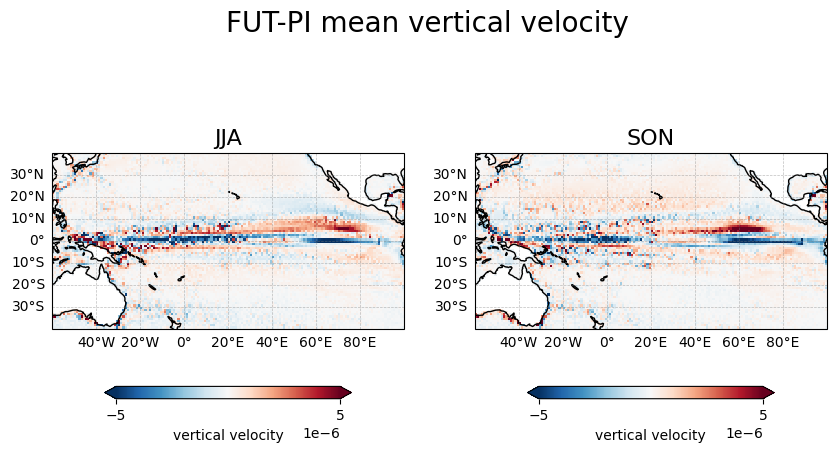

In [33]:
fig = plt.figure(figsize=(10,5))
vmi=-5e-6
vma=5e-6

lon=diff_SON.lon
lat=diff_SON.lat
ax = fig.add_subplot(1,2,1,projection=ccrs.PlateCarree(central_longitude=180))
proj = ccrs.PlateCarree(central_longitude=180)
im=ax.pcolormesh(lon,lat,diff_JJA.mean('member').mean('lev'),transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
ax.set_extent([120, 280, regbox[0], regbox[1]], crs=ccrs.PlateCarree())
plt.title('JJA',fontsize=16)
cbar1 = plt.colorbar(im,label='vertical velocity', orientation="horizontal",extend = 'both',ax=ax,drawedges=False, shrink = 0.7)
cbar1.set_ticks([vmi,vma])
gl=ax.gridlines(crs=ccrs.PlateCarree(central_longitude=180), draw_labels=True,linewidth=.5, color='gray', alpha=0.5, linestyle='--')
ax.coastlines()
gl.top_labels   = False
gl.right_labels = False

ax = fig.add_subplot(1,2,2,projection=ccrs.PlateCarree(central_longitude=180))
proj = ccrs.PlateCarree(central_longitude=180)
im=ax.pcolormesh(lon,lat,diff_SON.mean('member').mean('lev'),transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
ax.set_extent([120, 280, regbox[0], regbox[1]], crs=ccrs.PlateCarree())
plt.title('SON',fontsize=16)
cbar1 = plt.colorbar(im,label='vertical velocity m/s', orientation="horizontal",extend = 'both',ax=ax,drawedges=False, shrink = 0.7)
cbar1.set_ticks([vmi,vma])
gl=ax.gridlines(crs=ccrs.PlateCarree(central_longitude=180), draw_labels=True,linewidth=.5, color='gray', alpha=0.5, linestyle='--')
ax.coastlines()
gl.top_labels   = False
gl.right_labels = False

plt.suptitle('FUT-PI mean vertical velocity',fontsize=20)

In [ ]:
enPI,lnPI=select_events(tos,n34,regbox,1850,1880,timespi)
enFUT,lnFUT=select_events(tos,n34,regbox,2070,2100,timesfut)

In [ ]:
#enPI_u,lnPI_u = var_composites(upi,yrsPI,enPI,lnPI,24)
enPI_v,lnPI_v = var_composites(vpi.isel(member=slice(0,15)),yrsPI,enPI.isel(member=slice(0,15)),lnPI.isel(member=slice(0,15)),24)

In [ ]:
#enFUT_u,lnFUT_u = var_composites(ufut,yrsFUT,enFUT,lnFUT,24)
enFUT_v,lnFUT_v = var_composites(vfut,yrsFUT,enFUT.isel(member=slice(0,15)),lnFUT.isel(member=slice(0,15)),24)

In [ ]:
#lnPI_uq=lnPI_u.sel(time=slice(-7,-5)).mean('time').mean('member')

In [ ]:
lnPI_vq=lnPI_v.sel(time=slice(-1,1)).mean('time').mean('member').mean('lev')

In [ ]:
#lnFUT_uq=lnFUT_u.sel(time=slice(-7,-5)).mean('time').mean('member')

In [ ]:
lnFUT_vq=lnFUT_v.sel(time=slice(-1,1)).mean('time').mean('member').mean('lev')

In [ ]:
lnPI_vq

In [ ]:

plot_composites(lnPI_v.lon,lnPI_v.lat,lnPI_vq,regbox,'RdBu_r',-.01,.01,'current m/s',[-.01,0,.01],'PI DJF LN meridional current anomaly')



In [ ]:
#plot_composites(lnPI_v.lon,lnPI_v.lat,lnPI_v,regbox,'RdBu_r',-.01,.01,'meridional current m/s',[-.1,0,.1],'PI DJF LN meridional current anomaly')



In [ ]:
plot_composites(lnFUT_v.lon,lnFUT_v.lat,lnFUT_vq,regbox,'RdBu_r',-.01,.01,'current m/s',[-.01,0,.01],'FUT DJF LN meridional current anomaly')



In [ ]:
#plot_composites(lnFUT_v.lon,lnFUT_v.lat,lnFUT_v,regbox,'RdBu_r',-.01,.01,'meridional current m/s',[-.1,0,.1],'FUT DJF LN meridional current anomaly')


In [ ]:
diff_LN_peak=lnFUT_c-lnPI_c

In [ ]:
diff_LN_peak

In [ ]:
plot_composites(diff_LN_peak.lon,diff_LN_peak.lat,diff_LN_peak,regbox,'RdBu_r',-.005,.005,'wind stress N/m2',[-.005,0,.005],'Difference in DJF LN zonal wind stress anomaly FUT-PI')

